# 04 · Linking Clustering and Classification

**Goal:** use the customer segment found in notebook 02 as a new variable `cluster` and
check whether it improves churn prediction.

Comparison: **initial variables** vs **initial variables + `cluster`**, for the five models,
with the imbalance strategy selected in notebook 03.

⚠️ **No leakage:** the K-Means is a step of the classification pipeline (`ClusterFeature`).
It is fitted on the training data only (on each training fold during CV), never on the test
set, and it never sees `Churn`.

## Setup
This notebook is **self-contained**: it reloads the raw CSV and redefines the cleaning,
feature-engineering and preprocessing steps (explained in detail in notebook 01), so it
can be run on its own.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DATA = ROOT / "data" / "raw" / "wa-fn-usec-telco-customer.csv"
MODELS_DIR = ROOT / "models"
MLFLOW_URI = f"sqlite:///{ROOT / 'mlflow.db'}"

RANDOM_STATE = 42
TARGET = "Churn"
ID_COLUMN = "customerID"

### Cleaning & feature engineering
- `clean_raw`: convert `TotalCharges` to numeric (blank → NaN) and drop duplicated profiles.
- `add_features`: row-wise engineered features (no learned statistic → no leakage).

In [2]:
SERVICE_COLUMNS = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
                   "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]


def clean_raw(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    return df.drop_duplicates(subset=[c for c in df.columns if c != ID_COLUMN]).reset_index(drop=True)


def add_features(df):
    df = df.copy()
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
    df["num_services"] = (df[SERVICE_COLUMNS] == "Yes").sum(axis=1) + (df["InternetService"] != "No")
    df["avg_monthly_spend"] = np.where(df["tenure"] > 0,
                                       df["TotalCharges"] / df["tenure"].replace(0, np.nan),
                                       df["MonthlyCharges"])
    df["charges_per_service"] = df["MonthlyCharges"] / df["num_services"].clip(lower=1)
    df["is_month_to_month"] = (df["Contract"] == "Month-to-month").astype(int)
    df["auto_payment"] = df["PaymentMethod"].str.contains("automatic").astype(int)
    df["has_family"] = ((df["Partner"] == "Yes") | (df["Dependents"] == "Yes")).astype(int)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 60, 72],
                                labels=["0-12", "13-24", "25-48", "49-60", "61-72"]).astype(str)
    return df

### Preprocessing
Numeric → median imputation + standardization; binary → unchanged;
categorical → most-frequent imputation + one-hot encoding.

In [3]:
RAW_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges"]
RAW_BINARY = ["SeniorCitizen"]
RAW_CATEGORICAL = ["gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
                   "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
                   "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
                   "PaperlessBilling", "PaymentMethod"]

NUMERIC_FEATURES = RAW_NUMERIC + ["num_services", "avg_monthly_spend", "charges_per_service"]
BINARY_FEATURES = RAW_BINARY + ["is_month_to_month", "auto_payment", "has_family", "is_new_customer"]
CATEGORICAL_FEATURES = RAW_CATEGORICAL + ["tenure_group"]

# Subset used for segmentation (no target!)
CLUSTER_NUMERIC = ["tenure", "MonthlyCharges", "TotalCharges", "num_services"]
CLUSTER_BINARY = ["is_month_to_month", "auto_payment", "has_family", "SeniorCitizen"]
CLUSTER_CATEGORICAL = ["InternetService"]


def make_preprocessor(numeric=NUMERIC_FEATURES, binary=BINARY_FEATURES, categorical=CATEGORICAL_FEATURES):
    numeric_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                             ("scaler", StandardScaler())])
    categorical_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                 ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary",
                                                          sparse_output=False))])
    return ColumnTransformer([("num", numeric_pipe, numeric),
                              ("bin", "passthrough", binary),
                              ("cat", categorical_pipe, categorical)],
                             verbose_feature_names_out=False)

### Load data

In [4]:
df = clean_raw(pd.read_csv(RAW_DATA))
print("Dataset:", df.shape)

Dataset: (7021, 21)


### Modelling helpers
- `ClusterFeature`: adds the K-Means `cluster` (k = 4, see notebook 02) as a feature. The
  K-Means is **fitted on the training data only** (refitted on each CV fold).
- `build_pipeline`: raw customer rows → [feature engineering] → [cluster] → preprocessing →
  [oversampling] → model. Because everything lives in one `imblearn` pipeline, imputation,
  scaling and SMOTE/oversampling are fitted on training data only — **no data leakage** —
  and the oversampler is skipped at prediction time.

In [5]:
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

N_CLUSTERS = 4


def make_cluster_pipeline(n_clusters=N_CLUSTERS):
    return Pipeline([
        ("features", FunctionTransformer(add_features)),
        ("preprocess", make_preprocessor(CLUSTER_NUMERIC, CLUSTER_BINARY, CLUSTER_CATEGORICAL)),
        ("kmeans", KMeans(n_clusters=n_clusters, n_init=10, random_state=RANDOM_STATE)),
    ])


class ClusterFeature(BaseEstimator, TransformerMixin):
    def __init__(self, n_clusters=N_CLUSTERS):
        self.n_clusters = n_clusters

    def fit(self, X, y=None):
        self.pipeline_ = make_cluster_pipeline(self.n_clusters).fit(X)
        return self

    def transform(self, X):
        X = X.copy()
        X["cluster"] = self.pipeline_.predict(X).astype(str)
        return X


MODEL_NAMES = ["LogisticRegression", "DecisionTree", "RandomForest", "SVM", "XGBoost"]
IMBALANCE_STRATEGIES = ["none", "class_weight", "random_oversampling", "smote"]


def make_model(name, strategy="none", pos_weight=1.0):
    cw = "balanced" if strategy == "class_weight" else None
    model = {
        "LogisticRegression": lambda: LogisticRegression(max_iter=2000, class_weight=cw),
        "DecisionTree": lambda: DecisionTreeClassifier(class_weight=cw, random_state=RANDOM_STATE),
        "RandomForest": lambda: RandomForestClassifier(n_estimators=300, class_weight=cw,
                                                       random_state=RANDOM_STATE, n_jobs=1),
        "SVM": lambda: SVC(class_weight=cw, random_state=RANDOM_STATE),
        "XGBoost": lambda: XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4,
                                         eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=1,
                                         scale_pos_weight=pos_weight if strategy == "class_weight" else 1.0),
    }[name]()
    sampler = {"random_oversampling": RandomOverSampler(random_state=RANDOM_STATE),
               "smote": SMOTE(random_state=RANDOM_STATE)}.get(strategy)
    return model, sampler


def build_pipeline(name, strategy="none", pos_weight=1.0, n_clusters=None, feature_engineering=True):
    model, sampler = make_model(name, strategy, pos_weight)
    steps = []
    if feature_engineering:
        steps.append(("features", FunctionTransformer(add_features)))
        num, binary, cat = NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
    else:
        num, binary, cat = RAW_NUMERIC, RAW_BINARY, RAW_CATEGORICAL
    if n_clusters:
        steps.append(("cluster", ClusterFeature(n_clusters)))
        cat = cat + ["cluster"]
    steps.append(("preprocess", make_preprocessor(num, binary, cat)))
    if sampler is not None:
        steps.append(("sampler", sampler))
    steps.append(("model", model))
    return ImbPipeline(steps)


def predict_scores(model, X):
    """Churn probability, or decision score for SVM (enough for ROC-AUC)."""
    return model.predict_proba(X)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X)


def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {"precision": precision_score(y, y_pred), "recall": recall_score(y, y_pred),
            "f1": f1_score(y, y_pred), "roc_auc": roc_auc_score(y, predict_scores(model, X))}


def cv_scores(pipeline, X, y, cv):
    scores = cross_validate(pipeline, X, y, cv=cv, n_jobs=-1,
                            scoring=["precision", "recall", "f1", "roc_auc"])
    return {m: scores[f"test_{m}"].mean() for m in ["precision", "recall", "f1", "roc_auc"]}

### Train / test split
Same stratified 80/20 split (same `random_state`) in every notebook. The test set is
only used for the final evaluation; model selection uses 5-fold cross-validation on train.

In [6]:
X = df.drop(columns=[ID_COLUMN, TARGET])
y = (df[TARGET] == "Yes").astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
POS_WEIGHT = (y_train == 0).sum() / (y_train == 1).sum()   # for XGBoost scale_pos_weight
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Train {X_train.shape}, Test {X_test.shape}, churn rate train {y_train.mean():.3f}")

Train (5616, 19), Test (1405, 19), churn rate train 0.264


### MLflow helpers
Each run logs: model hyperparameters, preprocessing parameters, metrics, figures and the
fitted pipeline. Runs are stored in `mlflow.db` / `mlruns/` at the project root
(UI: `mlflow ui --backend-store-uri sqlite:///mlflow.db`).

In [7]:
import logging

import mlflow
import mlflow.sklearn

logging.getLogger("mlflow").setLevel(logging.ERROR)


def setup_mlflow(experiment_name):
    mlflow.set_tracking_uri(MLFLOW_URI)
    if mlflow.get_experiment_by_name(experiment_name) is None:
        mlflow.create_experiment(experiment_name,
                                 artifact_location=(ROOT / "mlruns" / experiment_name).as_uri())
    mlflow.set_experiment(experiment_name)


def preprocessing_params(pipeline):
    steps = dict(pipeline.steps)
    return {"feature_engineering": "features" in steps, "cluster_feature": "cluster" in steps,
            "numeric_imputer": "median", "categorical_imputer": "most_frequent",
            "scaler": "StandardScaler", "encoder": "OneHotEncoder",
            "resampling": type(steps["sampler"]).__name__ if "sampler" in steps else "none"}


def log_run(run_name, pipeline, metrics, params=None, figures=None, tags=None, log_model=True):
    with mlflow.start_run(run_name=run_name) as run:
        model = pipeline.named_steps["model"]
        hp = {k: v for k, v in model.get_params().items() if v is None or isinstance(v, (str, int, float, bool))}
        mlflow.log_param("model", type(model).__name__)
        mlflow.log_params({f"model__{k}": v for k, v in hp.items()})
        mlflow.log_params({f"prep__{k}": v for k, v in preprocessing_params(pipeline).items()})
        mlflow.log_params(params or {})
        mlflow.log_metrics({k: float(v) for k, v in metrics.items()})
        mlflow.set_tags(tags or {})
        for name, fig in (figures or {}).items():
            mlflow.log_figure(fig, f"{name}.png")
        if log_model:
            mlflow.sklearn.log_model(pipeline, name="model", serialization_format="cloudpickle",
                                     input_example=X_train.head(3))
        return run.info.run_id

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay

setup_mlflow("tele-cluster-classification")

# Best imbalance strategy per model (5-fold CV F1, notebook 03)
BEST_STRATEGY = {"LogisticRegression": "random_oversampling", "DecisionTree": "smote",
                 "RandomForest": "class_weight", "SVM": "class_weight", "XGBoost": "random_oversampling"}

## 1. The cluster as a customer profile
Fit the segmentation on the training customers, assign a cluster to train and test
customers, and look at the churn rate of each cluster.

In [9]:
cluster_step = ClusterFeature(N_CLUSTERS).fit(X_train)
train_clusters = cluster_step.transform(X_train)["cluster"]
test_clusters = cluster_step.transform(X_test)["cluster"]

summary = pd.DataFrame({
    "train customers": train_clusters.value_counts(),
    "train churn rate": y_train.groupby(train_clusters).mean(),
    "test churn rate": y_test.groupby(test_clusters).mean(),
    "avg tenure": X_train["tenure"].groupby(train_clusters).mean(),
    "avg monthly charges": X_train["MonthlyCharges"].groupby(train_clusters).mean(),
}).sort_values("train churn rate")
summary.round(2)

,train customers,train churn rate,test churn rate,avg tenure,avg monthly charges
cluster,,,,,
2,1226,0.07,0.09,30.47,21.10
0,1621,0.15,0.12,59.58,91.23
3,1336,0.25,0.26,20.38,51.86
1,1433,0.58,0.57,14.65,84.73


The four segments learned on the training set have very different churn rates, and the
**same ranking holds on the test set** → the cluster is a stable, informative profile.

How much information does the cluster carry **on its own**? A Logistic Regression using
only the `cluster` variable:

In [10]:
cluster_only = ImbPipeline([
    ("cluster", ClusterFeature(N_CLUSTERS)),
    ("encode", ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), ["cluster"])])),
    ("model", LogisticRegression(class_weight="balanced")),
])
pd.Series(cv_scores(cluster_only, X_train, y_train, cv), name="cluster only (CV)").round(3).to_frame()

,cluster only (CV)
precision,0.576
recall,0.556
f1,0.566
roc_auc,0.760


## 2. Cross-validated comparison
Same model, same strategy, same folds — only the presence of the `cluster` variable changes.

In [11]:
rows = []
for name in MODEL_NAMES:
    for with_cluster in [False, True]:
        pipe = build_pipeline(name, BEST_STRATEGY[name], POS_WEIGHT,
                              n_clusters=N_CLUSTERS if with_cluster else None)
        rows.append({"model": name, "variables": "initial + cluster" if with_cluster else "initial",
                     **cv_scores(pipe, X_train, y_train, cv)})
cv_comparison = pd.DataFrame(rows)
cv_comparison.pivot(index="model", columns="variables", values=["f1", "roc_auc", "recall", "precision"]).round(3)

f1                   roc_auc                    \
variables          initial initial + cluster initial initial + cluster   
model                                                                    
DecisionTree         0.506             0.504   0.664             0.663   
LogisticRegression   0.631             0.632   0.847             0.846   
RandomForest         0.614             0.607   0.830             0.830   
SVM                  0.630             0.630   0.827             0.827   
XGBoost              0.629             0.625   0.840             0.840   

                    recall                   precision                    
variables          initial initial + cluster   initial initial + cluster  
model                                                                     
DecisionTree         0.529             0.539     0.485             0.474  
LogisticRegression   0.801             0.801     0.520             0.523  
RandomForest         0.663             0.653     0.572             0.568  
SVM                  0.783             0.778     0.527             0.530  
XGBoost              0.756             0.749     0.539             0.537

## 3. Test-set comparison

In [12]:
rows, fitted = [], {}
for name in MODEL_NAMES:
    for with_cluster in [False, True]:
        variables = "initial + cluster" if with_cluster else "initial"
        pipe = build_pipeline(name, BEST_STRATEGY[name], POS_WEIGHT,
                              n_clusters=N_CLUSTERS if with_cluster else None).fit(X_train, y_train)
        fitted[(name, variables)] = pipe
        rows.append({"model": name, "variables": variables, **evaluate(pipe, X_test, y_test)})
test_comparison = pd.DataFrame(rows)
test_table = test_comparison.pivot(index="model", columns="variables", values=["f1", "roc_auc"])
test_table[("f1", "Δ")] = test_table[("f1", "initial + cluster")] - test_table[("f1", "initial")]
test_table[("roc_auc", "Δ")] = test_table[("roc_auc", "initial + cluster")] - test_table[("roc_auc", "initial")]
test_table.sort_index(axis=1).round(3)

f1                          roc_auc                    \
variables          initial initial + cluster      Δ initial initial + cluster   
model                                                                           
DecisionTree         0.510             0.504 -0.006   0.671             0.663   
LogisticRegression   0.623             0.624  0.001   0.841             0.841   
RandomForest         0.595             0.604  0.008   0.826             0.824   
SVM                  0.629             0.630  0.001   0.826             0.826   
XGBoost              0.621             0.621 -0.000   0.835             0.837   

                           
variables               Δ  
model                      
DecisionTree       -0.008  
LogisticRegression  0.000  
RandomForest       -0.001  
SVM                -0.001  
XGBoost             0.001

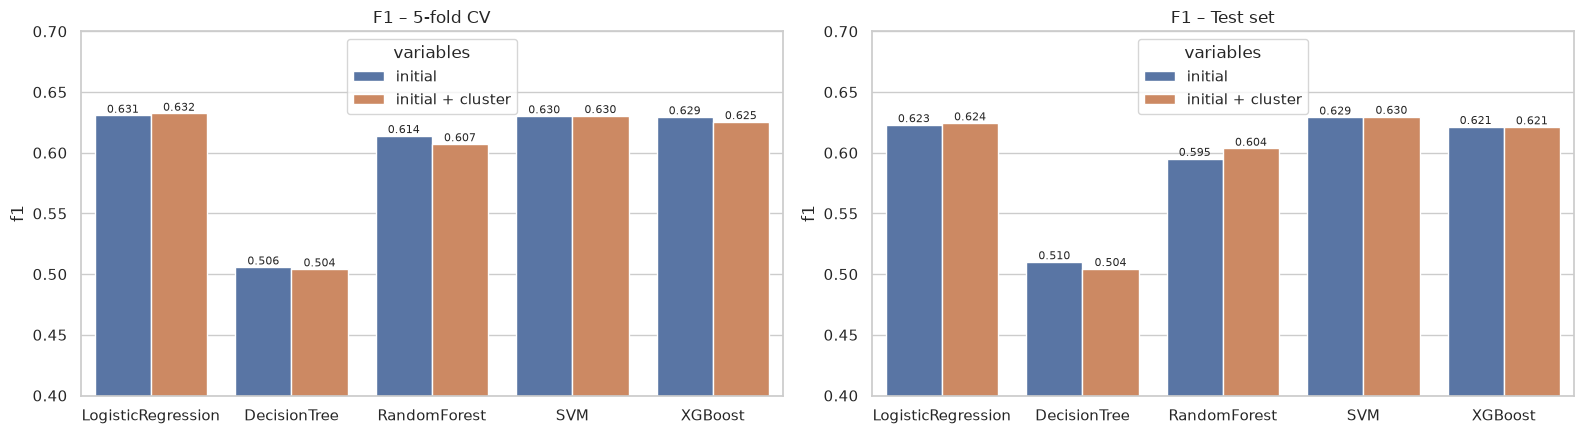

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, (data, title) in zip(axes, [(cv_comparison, "5-fold CV"), (test_comparison, "Test set")]):
    sns.barplot(data=data, x="model", y="f1", hue="variables", ax=ax)
    ax.set(title=f"F1 – {title}", ylim=(0.4, 0.7), xlabel="")
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", fontsize=8)
plt.tight_layout()
impact_fig = fig
plt.show()

## 4. MLflow tracking
One run per (model, variable set), tagged `with_cluster = true/false`.

In [14]:
cv_idx = cv_comparison.set_index(["model", "variables"])
test_idx = test_comparison.set_index(["model", "variables"])
for (name, variables), pipe in fitted.items():
    metrics = {**{f"cv_{m}": cv_idx.loc[(name, variables), m] for m in ["precision", "recall", "f1", "roc_auc"]},
               **{f"test_{m}": test_idx.loc[(name, variables), m] for m in ["precision", "recall", "f1", "roc_auc"]}}
    with_cluster = variables != "initial"
    log_run(f"{name}_{'cluster' if with_cluster else 'initial'}", pipe, metrics,
            params={"imbalance_strategy": BEST_STRATEGY[name], "n_clusters": N_CLUSTERS if with_cluster else 0},
            figures={"cluster_impact": impact_fig},
            tags={"stage": "cluster_comparison", "with_cluster": str(with_cluster).lower()})
print("Runs logged to MLflow")

Runs logged to MLflow


## 5. Analysis
- **The cluster is informative on its own**: with only the `cluster` variable, a Logistic
  Regression already reaches ROC-AUC ≈ 0.76 (F1 ≈ 0.57), and churn rates per segment range
  from ~7 % to ~58 %, identically on train and test.
- **But it brings no significant gain on top of the initial variables**: differences are
  within ±0.01 F1 / ROC-AUC in cross-validation and on the test set, i.e. within the
  fold-to-fold noise. Small gains for one model (e.g. Random Forest on test) are not
  confirmed by CV.
- **Why?** The cluster is a *compressed summary* of variables the classifier already
  receives (tenure, charges, contract, internet type, number of services). A supervised
  model can learn those patterns directly — and more finely — so the cluster is redundant.

**Conclusion:** segmentation is valuable for **business understanding and targeting**
(the "New fiber, at risk" segment concentrates churn), but it does not improve
prediction performance here. The cluster variable is still kept in the Streamlit app as
profile information for the user; the final model choice is made in notebook 05.

## Summary
| | Initial variables | Initial + cluster |
| --- | --- | --- |
| Best CV F1 (Logistic Regression) | 0.631 | 0.632 |
| Best test ROC-AUC (Logistic Regression) | 0.841 | 0.841 |

The cluster adds interpretability, not predictive power.